<a href="https://colab.research.google.com/github/JonaEmmOfCruz/Machine-learning/blob/main/Hands-on%203/Hands_on_3_Polynomial_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><strong>Regression in Machine Learning: Polynomial Regression.
</strong></h1>

La regresión polinomial permite ajustar curvas a los datos. Es útil cuando la relación entre la variable de entrada ($x$) y la variable de salida ($y$) no es recta, sino que sube, baja o cambia de dirección.

<br>

<br>

### **Modelo Matemático**

Un polinomio de grado $n$ se expresa como:

$$y = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_n x^n + \epsilon$$

<br>

||Descripción|
| -- |--|
| $\beta_0$ | El punto de partida donde la curva cruza el eje $Y$ |
| $\beta_1$, $\beta_2$, ..., $\beta_n$ | Pesos o multiplicadores asignados a <br> cada potencia de $x$. |
| $n$ | La potencia máxima. Determina cuántas <br> curvas o dobleces puede tener la función |
|$\epsilon$|La diferencia entre el valor real <br> y la predicción. |

<br>

<br>

### **¿Cómo aprende el modelo?**

Para hallar los coeficientes óptimos ($\hat{\beta}$), el modelo busca minimizar la Suma de Errores al Cuadrado (SSE):

<br>



$$\text{SSE} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

<br>

Gráficamente, mide la distancia vertical entre los puntos reales y la curva generada. Matemáticamente, encuentra los coeficientes óptimos resolviendo la ecuación matricial:

<br>

$$\hat{\beta} = (X^T X)^{-1} X^T y$$

<br>


### **Función de pérdida y solución por mínimos cuadrados (Least Squeares):**

El criterio de optimización consiste en minimizar la **Suma de Errores al Cuadrado (SSE)** entre las observaciones reales y las predicciones del modelo:

<br>

$$SSE = \sum_{i=1}^n (y_i - \hat{y}_i)^2 = |y - X \beta|^2$$

<br>

Resolviendo el problema vectorial se obtiene la solución para el vector de coeficientes óptimo $\hat{\beta}$:

<br>

$$\hat{\beta} = (X^T X)^{-1} X^Ty$$

<br>

Donde $X^T$ es la matriz transpuesta de $X$ y $(X^TX)^{-1}$ es su inversa

<br>

<br>

### **Predicción de nuevos valores:**

Una vez conocidos los coeficientes óptimos $\hat{\beta}$, la predicción para una nueva observacion $x^*$ se calcula evaluando el polinomio estimado:

<br>

$$\hat{y^*} = \hat{\beta}_0 + \hat{\beta}_1 x^* + \hat{\beta}_2 (x^*)^2 + \cdot \cdot \cdot + \hat{\beta}_n (x^*)^n$$

<br>

<br>

### **Métricas de evaluación**

| Métrica | <br> &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; Fórmula &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; <br> | Descripción |
| :--- | :--------------------: | :--- |
| **Suma de Errores <br> Cuadrados (SSE)** | $\sum_{i=1}^n (y_i - \hat{y}_i)^2$ | Mide el error acumulado total del modelo |
| **Error cuadrático <br> medio (MSE)** | $\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$ | Es el promedio de los errores cuadrados <br> penaliza desviaciones de la variable $y$ |
| **Raíz del MSE** | $\sqrt{MSE}$ | Magnitud del error expresado en las unidades <br> de la variable $y$ |
| **Coeficiente de <br> Determinación ($R^2$)** | $1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y}_i)^2}$ | Proporciona la variabilidad <br> de $y$ explicada por la curva polinomial |
| **Error absoluto <br> medio (MAE)** | $\frac{1}{n} \sum_{i=1}^n \lvert y_i - \hat{y}_i \rvert$ | Promedio de errores absolutos menos sensibles <br> a valores atípicos |

<br>

<h2><strong>Implementación en python</strong></h2>

<h3><strong>Importar librerías</strong></h3>

In [ ]:
# Se importa para operaciones numericas y generacion de datos
import numpy as np

# Se importa para estructurar los datos en DataFrames analíticos
import pandas as pd

# Se importa para crear graficos y visualizaciones dinamicas
import matplotlib.pyplot as plt

# Se importa para aplicar estilos a los graficos
import seaborn as sns

# Se importa para generar potencias polinomiales
from sklearn.preprocessing import PolynomialFeatures

# Importamos la regresión lineal
from sklearn.linear_model import LinearRegression

# Se importa para ajustar el modelo de minimos cuadrados
from sklearn.model_selection import train_test_split

# Se importa Pipeline y GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Se importa als metricas para evaluar la calidad del ajuste
from sklearn.metrics import r2_score, mean_squared_error

# Importamos mean_absolute_error de sklearn.metrics para el cálculo del MAE
from sklearn.metrics import mean_absolute_error

# Se fija la configuracion de fondo blanco con cuadrícula
sns.set_theme(style="whitegrid")


<h3><strong>Importación y recolección del dataset desde Drive</strong></h3>

In [ ]:
# Monto el Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Defino la ruta del archivo
ruta = '/content/drive/MyDrive/Colab Notebooks/dataset/dca.csv'

# Leo el archivo CSV
df = pd.read_csv(ruta)

# Muestro las primeras filas
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Variable_Predictora_X,Variable_Respuesta_Y
0,4.04,20.45
1,5.87,26.40
2,2.23,18.88
3,4.43,21.03
4,5.14,20.26


<h3><strong>Formateo de información</strong></h3>

In [ ]:
# 1. Identificar variable dependiente (Y) e independientes (X) dinámicamente
columna_y = 'Variable_Respuesta_Y'  # Ajusta al nombre real de la columna de salida en tu CSV

# Toma automáticamente la columna que no sea Y (y descarta columnas de índice como 'Unnamed: 0')
columnas_x = [col for col in df.columns if col not in [columna_y, 'Unnamed: 0']]

# 2. Formatear la información para scikit-learn
X = df[columnas_x].values
Y = df[columna_y].values

# 3. Confirmar la asignación
print(f"Variable(s) independiente(s) (X): {columnas_x}")
print(f"Variable dependiente (Y): {columna_y}")
print(f"Dimensiones de X: {X.shape}")

Variable(s) independiente(s) (X): ['Variable_Predictora_X']
Variable dependiente (Y): Variable_Respuesta_Y
Dimensiones de X: (200, 1)


<h3><strong>Gráfico del DataSet</strong></h3>

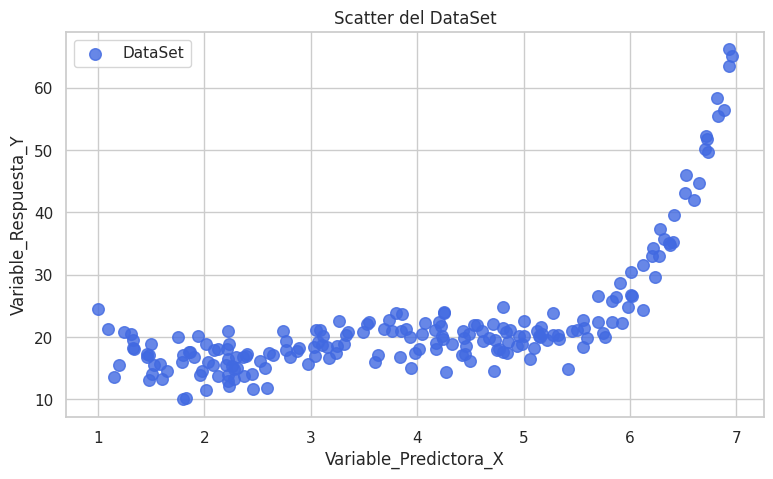

In [ ]:
# Se crea la imagen
plt.figure(figsize=(9, 5))

# Dibujo el grafico de dispersión
plt.scatter(df[columna_x], df[columna_y], color='royalblue', edgecolor='royalblue', s=70, alpha=0.8, label='DataSet')

# Asignar el título
plt.title('Scatter del DataSet', fontsize=12)

# Defino el eje x
plt.xlabel(f"{columna_x}", fontsize=12)

# Defino el eje y
plt.ylabel(f"{columna_y}", fontsize=12)

# Mostrar la leyenda descriptiva
plt.legend(fontsize=11)

plt.show()


<h3><strong>Selección y división de los datos de entrenamiento y prueba</strong></h3>

In [ ]:
# Se reserva el 30% para prueba y 70% para entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42)


<h3><strong>Selección para obtener el Grado Óptimo</strong></h3>

In [ ]:
grados_a_probar = [4, 5, 6, 7, 8, 9]
grado_optimo = None
mejor_r2_val = -float('inf')

scores_train = []
scores_val = []

for grado in grados_a_probar:
  # 1. Transformar X a potencias (1, x, x^2, ..., x^n)
  poly_temp = PolynomialFeatures(degree=grado, include_bias=False)
  X_tr_p = poly_temp.fit_transform(X_train)
  X_te_p = poly_temp.transform(X_test)

  # 2. Entrenar regresión lineal sobre las potencias
  mod_temp = LinearRegression()
  mod_temp.fit(X_tr_p, y_train)

  # 3. Calcular R^2
  score_train = r2_score(y_train, mod_temp.predict(X_tr_p))
  score_test = r2_score(y_test, mod_temp.predict(X_te_p))

  scores_train.append(score_train)
  scores_val.append(score_test)

  # 4. Guardar el mejor grado según el score de prueba
  if score_test > mejor_r2_val:
    mejor_r2_val = score_test
    grado_optimo = grado

print(f'Grado Óptimo n = {grado_optimo}')  # Resultado: n = 4

Grado Óptimo n = 4


<h3><strong>Grafjica de la selección del grado óptimo</strong></h3>

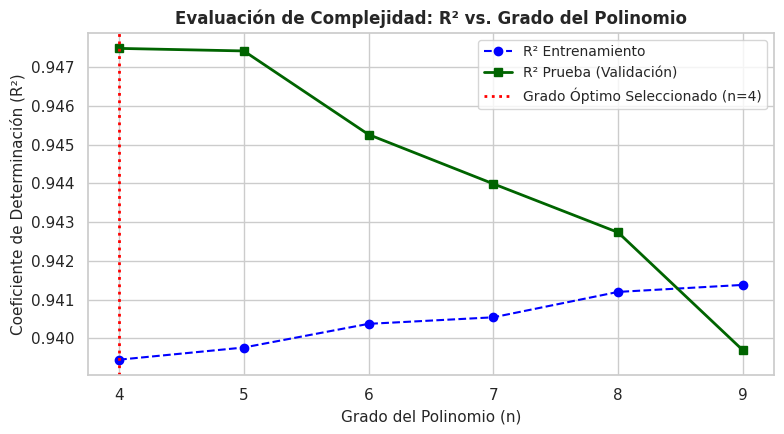

 
Grado Óptimo Seleccionado: n = 4


In [ ]:
plt.figure(figsize=(8, 4.5))
plt.plot(
    grados_a_probar,
    scores_train,
    marker='o',
    linestyle='--',
    color='blue',
    label='R² Entrenamiento',
)
plt.plot(
    grados_a_probar,
    scores_val,
    marker='s',
    linewidth=2,
    color='darkgreen',
    label='R² Prueba (Validación)',
)

plt.axvline(
    x=grado_optimo,
    color='red',
    linestyle=':',
    linewidth=2,
    label=f'Grado Óptimo Seleccionado (n={grado_optimo})',
)

plt.title(
    'Evaluación de Complejidad: R² vs. Grado del Polinomio',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Grado del Polinomio (n)', fontsize=11)
plt.ylabel('Coeficiente de Determinación (R²)', fontsize=11)
plt.xticks(grados_a_probar)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f' \nGrado Óptimo Seleccionado: n = {grado_optimo}')

<h3><strong>Entrenamiento del modelo</strong></h3>

In [ ]:
# Crear transformador polinomial final
polinomio = PolynomialFeatures(degree=grado_optimo, include_bias=False)
X_train_poly = polinomio.fit_transform(X_train)
X_test_poly = polinomio.transform(X_test)

# Ajustar modelo
modelo = LinearRegression()
modelo.fit(X_train_poly, y_train)

LinearRegression()

<h3><strong>Extraer los coeficientes y la generación de la curva de predicción ajustada</strong></h3>

In [ ]:
# Extraer parámetros
beta_0 = round(modelo.intercept_, 4)
coefs = [round(c, 4) for c in modelo.coef_]

# Generar 200 puntos equiespaciados
X_continuo = np.linspace(X.min() - 0.5, X.max() + 0.5, 200).reshape(-1, 1)

# Transformar al grado óptimo y predecir
X_continuo_poly = polinomio.transform(X_continuo)
y_continuo_pred = modelo.predict(X_continuo_poly)

<h3><strong>Curva polinomial ajustada</strong></h3>

In [ ]:
# Genero 200 puntos dentro del rango en X
X_continuo = np.linspace(X.min() - 0.5, X.max() + 0.5, 200).reshape(-1, 1)

# Dominio continuo con el objeto polinomio de grado óptimo
X_continuo_poly = polinomio.transform(X_continuo)

# Calcular las predicciones del modelo
y_continuo_pred = modelo.predict(X_continuo_poly)

<h3><strong>Grafico de los puntos del conjunto de entrenamiento</strong></h3>

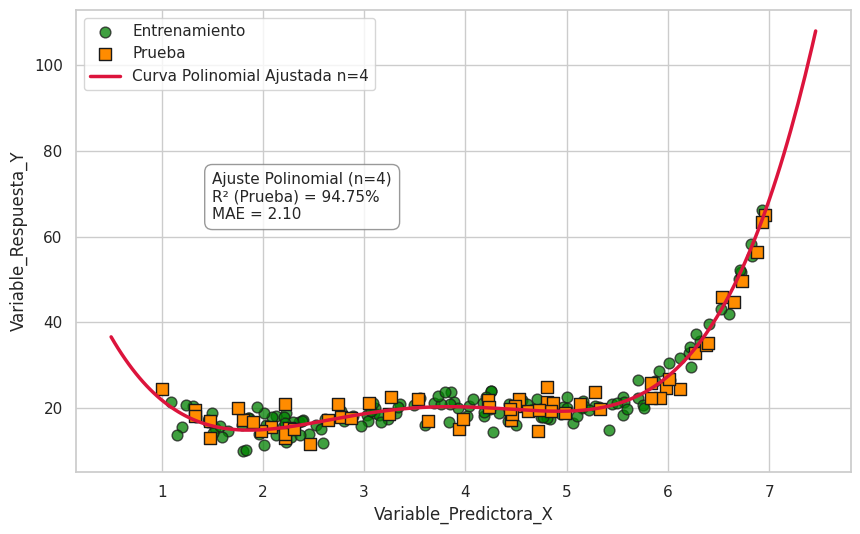

In [ ]:
plt.figure(figsize=(10, 6))

# Puntos del conjunto de entrenamiento
plt.scatter(X_train, y_train, color='green', edgecolor='k', s=60, alpha=0.75, label='Entrenamiento')

# Puntos del conjunto de prueba
plt.scatter(X_test, y_test, color='darkorange', marker='s', edgecolor='k', s=70, label='Prueba')

# Curva continua al grado óptimo
plt.plot(X_continuo, y_continuo_pred, color='crimson', linewidth=2.5, label=f'Curva Polinomial Ajustada n={grado_optimo}')

# Eje x
plt.xlabel(f"{columna_x}", fontsize=12)

# Eje y
plt.ylabel(f"{columna_y}", fontsize=12)

plt.legend(fontsize=11)

plt.text(
    X.min() + 0.5,
    y_train.max() - 2,
    f'Ajuste Polinomial (n={grado_optimo})\n'
    f'R² (Prueba) = {r2_test:.2%}\n'
    f'MAE = {mae_test:.2f}',
    fontsize=11,
    bbox=dict(
        boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray'
    ),
)
plt.show()

<h3><strong>Resultados de la regresion polinomial</strong></h3>

In [ ]:
# 1. Mostrar coeficientes y ecuación matemática del modelo
print(f"Intercepto (Beta 0): {modelo.intercept_:.4f}\n")
print("Coeficientes por término:")
for i, coef in enumerate(modelo.coef_, start=1):
  print(f"  • B{i} (x^{i}): {coef:,.6f}")

# Construcción elegante de la ecuación en LaTeX / Texto
terminos = []
for i, coef in enumerate(modelo.coef_, start=1):
  signo = '+' if coef >= 0 else '-'
  terminos.append(f'{signo} {abs(coef):.4f}x^{i}')

ecuacion_str = f'y_hat = {modelo.intercept_:.2f} ' + ' '.join(terminos)
print(f'\nEcuación ajustada:\n{ecuacion_str}\n')

# 2. Resumen comparativo de métricas en un solo DataFrame
df_resumen_metricas = pd.DataFrame({
    'Métrica de evaluación': [
        'SSE (Suma Errores Cuadrados)',
        'MSE (Error Cuadrático Medio)',
        'MAE (Error Absoluto Medio)',
        'R² (Coef. Determinación)',
    ],
    'Entrenamiento': [
        f'{sse_train:,.2f}',
        f'{mse_train:,.2f}',
        f'{mae_train:,.2f}',
        f'{r2_train:.4f}',
    ],
    'Prueba': [
        f'{sse_test:,.2f}',
        f'{mse_test:,.2f}',
        f'{mae_test:,.2f}',
        f'{r2_test:.4f}',
    ],
})

display(df_resumen_metricas)

Intercepto (Beta 0): 64.3079

Coeficientes por término:
  • B1 (x^1): -71.516337
  • B2 (x^2): 35.790597
  • B3 (x^3): -7.198514
  • B4 (x^4): 0.508202

Ecuación ajustada:
y_hat = 64.31 - 71.5163x^1 + 35.7906x^2 - 7.1985x^3 + 0.5082x^4



,Métrica de evaluación,Entrenamiento,Prueba
0,SSE (Suma Errores Cuadrados),722.97,416.15
1,MSE (Error Cuadrático Medio),5.16,6.94
2,MAE (Error Absoluto Medio),1.83,2.10
3,R² (Coef. Determinación),0.9395,0.9475
